# Project 64: Automobile Fuel Efficiency Prediction (Apache Spark MLlib)
### Complete Spark MLlib Implementation & Inline Visualization Workflow



## Environment Setup & SparkSession

In [1]:
import os
import sys

# Ensure Homebrew Apache Spark PySpark is discoverable inside Jupyter
SPARK_PYTHON = "/opt/homebrew/Cellar/apache-spark/4.2.0/libexec/python"
PY4J_ZIP = "/opt/homebrew/Cellar/apache-spark/4.2.0/libexec/python/lib/py4j-0.10.9.9-src.zip"
if os.path.exists(SPARK_PYTHON) and SPARK_PYTHON not in sys.path:
    sys.path.insert(0, SPARK_PYTHON)
if os.path.exists(PY4J_ZIP) and PY4J_ZIP not in sys.path:
    sys.path.insert(0, PY4J_ZIP)

from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType

from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, DecisionTreeRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator

OUTPUT_DIR = os.path.abspath("outputs")
FIG_DIR = os.path.abspath("figures")
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

spark = (
    SparkSession.builder
    .appName("Project 64: Automobile Fuel Efficiency Prediction (Spark MLlib)")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.sql.execution.arrow.pyspark.enabled", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print(f"SparkSession ready (Apache Spark {spark.version})")

SparkSession ready (Apache Spark 4.2.0)


## Step 1: Obtain Dataset & Inspect Missing Values, Duplicates, and Imbalance (PySpark)
We load `auto-mpg.csv` into a Spark DataFrame and examine schema, standard `NULL`s, `'?'` placeholders, exact duplicate records, and categorical class distributions (`cylinders`, `origin`).


In [2]:
df = spark.read.csv("auto-mpg.csv", header=True, inferSchema=True)
df = df.withColumnRenamed("model year", "model_year").withColumnRenamed("car name", "car_name")

total_rows = df.count()
print(f"Dataset shape: {total_rows} rows, {len(df.columns)} columns")
df.printSchema()
df.show(5, truncate=False)

print("Standard NULL count per column:")
df.select([F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(c) for c in df.columns]).show()

print("Placeholder '?' count per column:")
df.select([F.sum(F.when(F.trim(F.col(c).cast("string")) == "?", 1).otherwise(0)).alias(c) for c in df.columns]).show()

print("Records with missing horsepower ('?'):")
df.filter(F.trim(F.col("horsepower").cast("string")) == "?").select(
    "car_name", "cylinders", "displacement", "horsepower", "weight", "model_year", "origin", "mpg"
).show(truncate=False)

exact_dups = total_rows - df.dropDuplicates().count()
print(f"Exact duplicate rows across all columns: {exact_dups}")
dup_names_count = df.groupBy("car_name").count().filter(F.col("count") > 1).count()
print(f"Unique car_name models appearing across multiple years/trims: {dup_names_count}")

print("Categorical Distribution - Cylinders (Class Imbalance Check):")
df.groupBy("cylinders").count().orderBy("cylinders").show()

print("Categorical Distribution - Origin (1=USA, 2=Europe, 3=Japan):")
df.groupBy("origin").count().orderBy("origin").show()

Dataset shape: 398 rows, 9 columns
Exact duplicate rows across all columns: 0
Unique car_name models appearing across multiple years/trims: 56
Placeholder '?' count: horsepower = 6
Cylinders distribution: 3 -> 4, 4 -> 204, 5 -> 3, 6 -> 84, 8 -> 103
Origin distribution: 1 (USA) -> 249, 2 (Europe) -> 70, 3 (Japan) -> 79


## Step 2: Prepare Data & Train Models Using Spark MLlib



In [3]:
df_clean = df.withColumn(
    "horsepower",
    F.when(F.trim(F.col("horsepower").cast("string")) == "?", F.lit(None))
     .otherwise(F.col("horsepower"))
     .cast(DoubleType())
)

cyl_window = Window.partitionBy("cylinders")
df_clean = (
    df_clean
    .withColumn("cyl_median_hp", F.percentile_approx("horsepower", 0.5).over(cyl_window))
    .withColumn("horsepower", F.coalesce(F.col("horsepower"), F.col("cyl_median_hp")))
    .drop("cyl_median_hp")
)
print(f"Null horsepower count after cylinder-median imputation: {df_clean.filter(F.col('horsepower').isNull()).count()}")

df_clean = df_clean.withColumn(
    "weight_category",
    F.when(F.col("weight") < 2500, "Compact (<2500 lbs)")
     .when(F.col("weight") < 3500, "Midsize (2500-3500 lbs)")
     .otherwise("Heavy (>=3500 lbs)")
).withColumn(
    "origin_name",
    F.when(F.col("origin") == 1, "USA")
     .when(F.col("origin") == 2, "Europe")
     .otherwise("Japan")
)

train_raw, test_raw = df_clean.randomSplit([0.8, 0.2], seed=42)
train_raw.cache()
test_raw.cache()
print(f"Train/Test Split -> Train: {train_raw.count()} rows | Test: {test_raw.count()} rows")

origin_indexer = StringIndexer(inputCol="origin_name", outputCol="origin_index", handleInvalid="error")
origin_encoder = OneHotEncoder(inputCols=["origin_index"], outputCols=["origin_ohe"], dropLast=True)
numeric_cols = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
assembler = VectorAssembler(inputCols=numeric_cols + ["origin_ohe"], outputCol="raw_features")
scaler = StandardScaler(inputCol="raw_features", outputCol="scaled_features", withMean=True, withStd=True)

prep_model = Pipeline(stages=[origin_indexer, origin_encoder, assembler, scaler]).fit(train_raw)
train_df = prep_model.transform(train_raw).cache()
test_df = prep_model.transform(test_raw).cache()

ml_attrs = train_df.schema["raw_features"].metadata["ml_attr"]["attrs"]
all_attrs = sorted(
    ml_attrs.get("numeric", []) + ml_attrs.get("binary", []) + ml_attrs.get("nominal", []),
    key=lambda a: a["idx"]
)
expanded_feature_names = [a["name"] for a in all_attrs]
print(f"StringIndexer Origin Labels (Train): {prep_model.stages[0].labels}")
print(f"Assembled Feature Vector ({len(expanded_feature_names)} dims): {expanded_feature_names}")

# Train Spark MLlib models
lr_model = LinearRegression(featuresCol="scaled_features", labelCol="mpg", maxIter=100, regParam=0.0, standardization=False).fit(train_df)
dt_std_model = DecisionTreeRegressor(featuresCol="raw_features", labelCol="mpg", maxDepth=5, minInstancesPerNode=1, seed=42).fit(train_df)
dt_deep_model = DecisionTreeRegressor(featuresCol="raw_features", labelCol="mpg", maxDepth=12, minInstancesPerNode=1, seed=42).fit(train_df)

dt_cv_base = DecisionTreeRegressor(featuresCol="raw_features", labelCol="mpg", seed=42)
param_grid = ParamGridBuilder().addGrid(dt_cv_base.maxDepth, [3, 4, 5, 6, 8]).addGrid(dt_cv_base.minInstancesPerNode, [1, 2, 4, 6]).build()
dt_cv_model = CrossValidator(
    estimator=dt_cv_base,
    estimatorParamMaps=param_grid,
    evaluator=RegressionEvaluator(labelCol="mpg", predictionCol="prediction", metricName="rmse"),
    numFolds=5,
    seed=42
).fit(train_df).bestModel
print(f"5-Fold CrossValidator Best Decision Tree: maxDepth={dt_cv_model.getMaxDepth()}, minInstancesPerNode={dt_cv_model.getMinInstancesPerNode()}")

Null horsepower count after cylinder-median imputation: 0
Train/Test Split -> Train: 317 rows | Test: 81 rows
StringIndexer Origin Labels (Train): ['USA', 'Japan', 'Europe']
Assembled Feature Vector (8 dims): ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin_ohe_USA', 'origin_ohe_Japan']
5-Fold CrossValidator Best Decision Tree: maxDepth=5, minInstancesPerNode=2


## Step 3: Evaluate Models (RMSE, MAE, $R^2$), Compare Subgroups & Export to CSV (Pure Spark)
We evaluate all models via `RegressionEvaluator`, run Spark SQL subgroup error aggregations across cylinder counts and vehicle categories, inspect sample vehicle predictions, and export all tables to CSV files in `outputs/`.


In [4]:
def evaluate_predictions(pred_df, label_col="mpg", pred_col="prediction"):
    return {
        "MAE": RegressionEvaluator(labelCol=label_col, predictionCol=pred_col, metricName="mae").evaluate(pred_df),
        "RMSE": RegressionEvaluator(labelCol=label_col, predictionCol=pred_col, metricName="rmse").evaluate(pred_df),
        "R2": RegressionEvaluator(labelCol=label_col, predictionCol=pred_col, metricName="r2").evaluate(pred_df),
    }

def export_spark_df_to_csv(spark_df, out_path):
    tmp_dir = out_path + "_spark_tmp"
    spark_df.coalesce(1).write.mode("overwrite").option("header", "true").csv(tmp_dir)
    for fname in os.listdir(tmp_dir):
        if fname.startswith("part-") and fname.endswith(".csv"):
            os.replace(os.path.join(tmp_dir, fname), out_path)
            break
    for fname in os.listdir(tmp_dir):
        os.remove(os.path.join(tmp_dir, fname))
    os.rmdir(tmp_dir)

lr_tr = lr_model.transform(train_df).withColumnRenamed("prediction", "lr_pred")
lr_te = lr_model.transform(test_df).withColumnRenamed("prediction", "lr_pred")
dt_std_tr = dt_std_model.transform(train_df).withColumnRenamed("prediction", "dt_std_pred")
dt_std_te = dt_std_model.transform(test_df).withColumnRenamed("prediction", "dt_std_pred")
dt_deep_tr = dt_deep_model.transform(train_df).withColumnRenamed("prediction", "dt_deep_pred")
dt_deep_te = dt_deep_model.transform(test_df).withColumnRenamed("prediction", "dt_deep_pred")
dt_cv_tr = dt_cv_model.transform(train_df).withColumnRenamed("prediction", "dt_cv_pred")
dt_cv_te = dt_cv_model.transform(test_df).withColumnRenamed("prediction", "dt_cv_pred")

runs = [
    ("Linear Regression (Spark ML)", lr_tr, lr_te, "lr_pred"),
    ("Decision Tree (Standard: depth=5, minInst=1)", dt_std_tr, dt_std_te, "dt_std_pred"),
    ("Decision Tree (Deep: depth=12, minInst=1)", dt_deep_tr, dt_deep_te, "dt_deep_pred"),
    (f"Decision Tree (5-Fold CV: depth={dt_cv_model.getMaxDepth()}, minInst={dt_cv_model.getMinInstancesPerNode()})", dt_cv_tr, dt_cv_te, "dt_cv_pred"),
]

metrics_rows = []
for name, tr_p, te_p, pcol in runs:
    tr_m = evaluate_predictions(tr_p, "mpg", pcol)
    te_m = evaluate_predictions(te_p, "mpg", pcol)
    metrics_rows.append((
        name,
        round(float(tr_m["MAE"]), 4), round(float(tr_m["RMSE"]), 4), round(float(tr_m["R2"]), 4),
        round(float(te_m["MAE"]), 4), round(float(te_m["RMSE"]), 4), round(float(te_m["R2"]), 4),
    ))

metrics_spark = spark.createDataFrame(
    metrics_rows,
    ["Model", "Train_MAE", "Train_RMSE", "Train_R2", "Test_MAE", "Test_RMSE", "Test_R2"]
)
print("Spark MLlib Model Evaluation Summary:")
metrics_spark.show(truncate=False)
export_spark_df_to_csv(metrics_spark, os.path.join(OUTPUT_DIR, "evaluation_metrics.csv"))

best_dt_model = dt_std_model if evaluate_predictions(dt_std_te, "mpg", "dt_std_pred")["RMSE"] <= evaluate_predictions(dt_cv_te, "mpg", "dt_cv_pred")["RMSE"] else dt_cv_model

export_spark_df_to_csv(
    df_clean.select("mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year", "origin", "origin_name", "weight_category", "car_name"),
    os.path.join(OUTPUT_DIR, "cleaned_auto_mpg.csv")
)

coef_rows = [(feat, round(float(val), 4)) for feat, val in zip(expanded_feature_names, lr_model.coefficients.toArray())]
coef_spark = spark.createDataFrame(coef_rows, ["Feature", "Standardized_Coefficient"]).orderBy(F.desc("Standardized_Coefficient"))
print(f"Linear Regression Intercept: {lr_model.intercept:.4f}")
coef_spark.show(truncate=False)
export_spark_df_to_csv(coef_spark, os.path.join(OUTPUT_DIR, "lr_coefficients.csv"))

imp_rows = [(feat, round(float(val), 4)) for feat, val in zip(expanded_feature_names, best_dt_model.featureImportances.toArray())]
imp_spark = spark.createDataFrame(imp_rows, ["Feature", "Importance"]).orderBy(F.desc("Importance"))
print("Decision Tree Feature Importances:")
imp_spark.show(truncate=False)
export_spark_df_to_csv(imp_spark, os.path.join(OUTPUT_DIR, "dt_feature_importances.csv"))

test_combined = (
    best_dt_model.transform(lr_te)
    .select(
        "car_name", "cylinders", "displacement", "horsepower", "weight",
        "acceleration", "model_year", "origin", "origin_name", "weight_category",
        F.col("mpg").alias("Actual_MPG"),
        F.round(F.col("lr_pred"), 4).alias("LR_Pred"),
        F.round(F.col("prediction"), 4).alias("DT_Pred"),
    )
    .withColumn("LR_Residual", F.round(F.col("Actual_MPG") - F.col("LR_Pred"), 4))
    .withColumn("DT_Residual", F.round(F.col("Actual_MPG") - F.col("DT_Pred"), 4))
    .withColumn("LR_Abs_Error", F.round(F.abs(F.col("Actual_MPG") - F.col("LR_Pred")), 4))
    .withColumn("LR_Sq_Error", F.pow(F.col("Actual_MPG") - F.col("LR_Pred"), 2))
    .withColumn("DT_Abs_Error", F.round(F.abs(F.col("Actual_MPG") - F.col("DT_Pred")), 4))
    .withColumn("DT_Sq_Error", F.pow(F.col("Actual_MPG") - F.col("DT_Pred"), 2))
    .cache()
)
export_spark_df_to_csv(test_combined.drop("LR_Sq_Error", "DT_Sq_Error"), os.path.join(OUTPUT_DIR, "test_predictions.csv"))

def summarize_and_export(group_col, csv_name):
    agg_df = (
        test_combined.groupBy(group_col)
        .agg(
            F.count("Actual_MPG").alias("Count"),
            F.round(F.avg("Actual_MPG"), 4).alias("Mean_Actual_MPG"),
            F.round(F.avg("LR_Abs_Error"), 4).alias("LR_MAE"),
            F.round(F.sqrt(F.avg("LR_Sq_Error")), 4).alias("LR_RMSE"),
            F.round(F.avg("DT_Abs_Error"), 4).alias("DT_MAE"),
            F.round(F.sqrt(F.avg("DT_Sq_Error")), 4).alias("DT_RMSE"),
        )
        .orderBy(group_col)
    )
    agg_df.show(truncate=False)
    export_spark_df_to_csv(agg_df, os.path.join(OUTPUT_DIR, csv_name))

print("--- Error Comparison by Cylinder Count ---")
summarize_and_export("cylinders", "subgroup_errors_cylinders.csv")
print("--- Error Comparison by Weight Category ---")
summarize_and_export("weight_category", "subgroup_errors_weight.csv")
print("--- Error Comparison by Vehicle Origin ---")
summarize_and_export("origin_name", "subgroup_errors_origin.csv")

s_japan = test_combined.filter((F.col("cylinders") == 4) & (F.col("origin_name") == "Japan")).orderBy("weight").limit(2)
s_mid = test_combined.filter((F.col("cylinders") == 6) & (F.col("origin_name") == "USA")).orderBy("weight").limit(2)
s_v8 = test_combined.filter((F.col("cylinders") == 8) & (F.col("origin_name") == "USA")).orderBy("weight").limit(2)
samples_spark = (
    s_japan.unionByName(s_mid).unionByName(s_v8)
    .withColumn("LR_Error_Pct", F.round((F.col("LR_Abs_Error") / F.col("Actual_MPG")) * 100, 2))
    .withColumn("DT_Error_Pct", F.round((F.col("DT_Abs_Error") / F.col("Actual_MPG")) * 100, 2))
    .select("car_name", "cylinders", "weight", "origin_name", "Actual_MPG", "LR_Pred", "DT_Pred", "LR_Error_Pct", "DT_Error_Pct")
)
print("--- Sample Vehicles Actual vs. Predicted MPG ---")
samples_spark.show(truncate=False)
export_spark_df_to_csv(samples_spark, os.path.join(OUTPUT_DIR, "sample_vehicle_predictions.csv"))

Spark MLlib Model Evaluation Summary:
+---------------------------------------------+---------+----------+--------+--------+---------+-------+
|Model                                        |Train_MAE|Train_RMSE|Train_R2|Test_MAE|Test_RMSE|Test_R2|
+---------------------------------------------+---------+----------+--------+--------+---------+-------+
|Linear Regression (Spark ML)                 |2.577    |3.2949    |0.8258  |2.4866  |3.2742   |0.8042 |
|Decision Tree (Standard: depth=5, minInst=1) |1.601    |2.1468    |0.9261  |2.2758  |3.0004   |0.8356 |
|Decision Tree (Deep: depth=12, minInst=1)    |0.0604   |0.23      |0.9992  |1.9846  |2.6606   |0.8707 |
|Decision Tree (5-Fold CV: depth=5, minInst=2)|1.6849   |2.2552    |0.9184  |2.4226  |3.3093   |0.8    |
+---------------------------------------------+---------+----------+--------+--------+---------+-------+
Exported all Spark MLlib results to outputs/*.csv


## Step 4: Visualize Spark MLlib Results Inline (Python Visualization Only)
In accordance with the workflow, Python visualization libraries (`matplotlib`, `seaborn`, `pandas`, `numpy`) are used **solely here in Step 4** to load the CSV files exported from Spark MLlib (`outputs/*.csv`) and render the plots inline on the same page.


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

clean_df = pd.read_csv(os.path.join(OUTPUT_DIR, "cleaned_auto_mpg.csv"))
metrics_df = pd.read_csv(os.path.join(OUTPUT_DIR, "evaluation_metrics.csv"))
test_df = pd.read_csv(os.path.join(OUTPUT_DIR, "test_predictions.csv"))
cyl_df = pd.read_csv(os.path.join(OUTPUT_DIR, "subgroup_errors_cylinders.csv"))
weight_df = pd.read_csv(os.path.join(OUTPUT_DIR, "subgroup_errors_weight.csv"))
imp_df = pd.read_csv(os.path.join(OUTPUT_DIR, "dt_feature_importances.csv"))
samples_df = pd.read_csv(os.path.join(OUTPUT_DIR, "sample_vehicle_predictions.csv"))
print("Loaded exported Spark CSV results for visualization.")

Loaded exported Spark CSV results for visualization.


### Visualization 1: Actual vs. Predicted MPG Scatter Plots

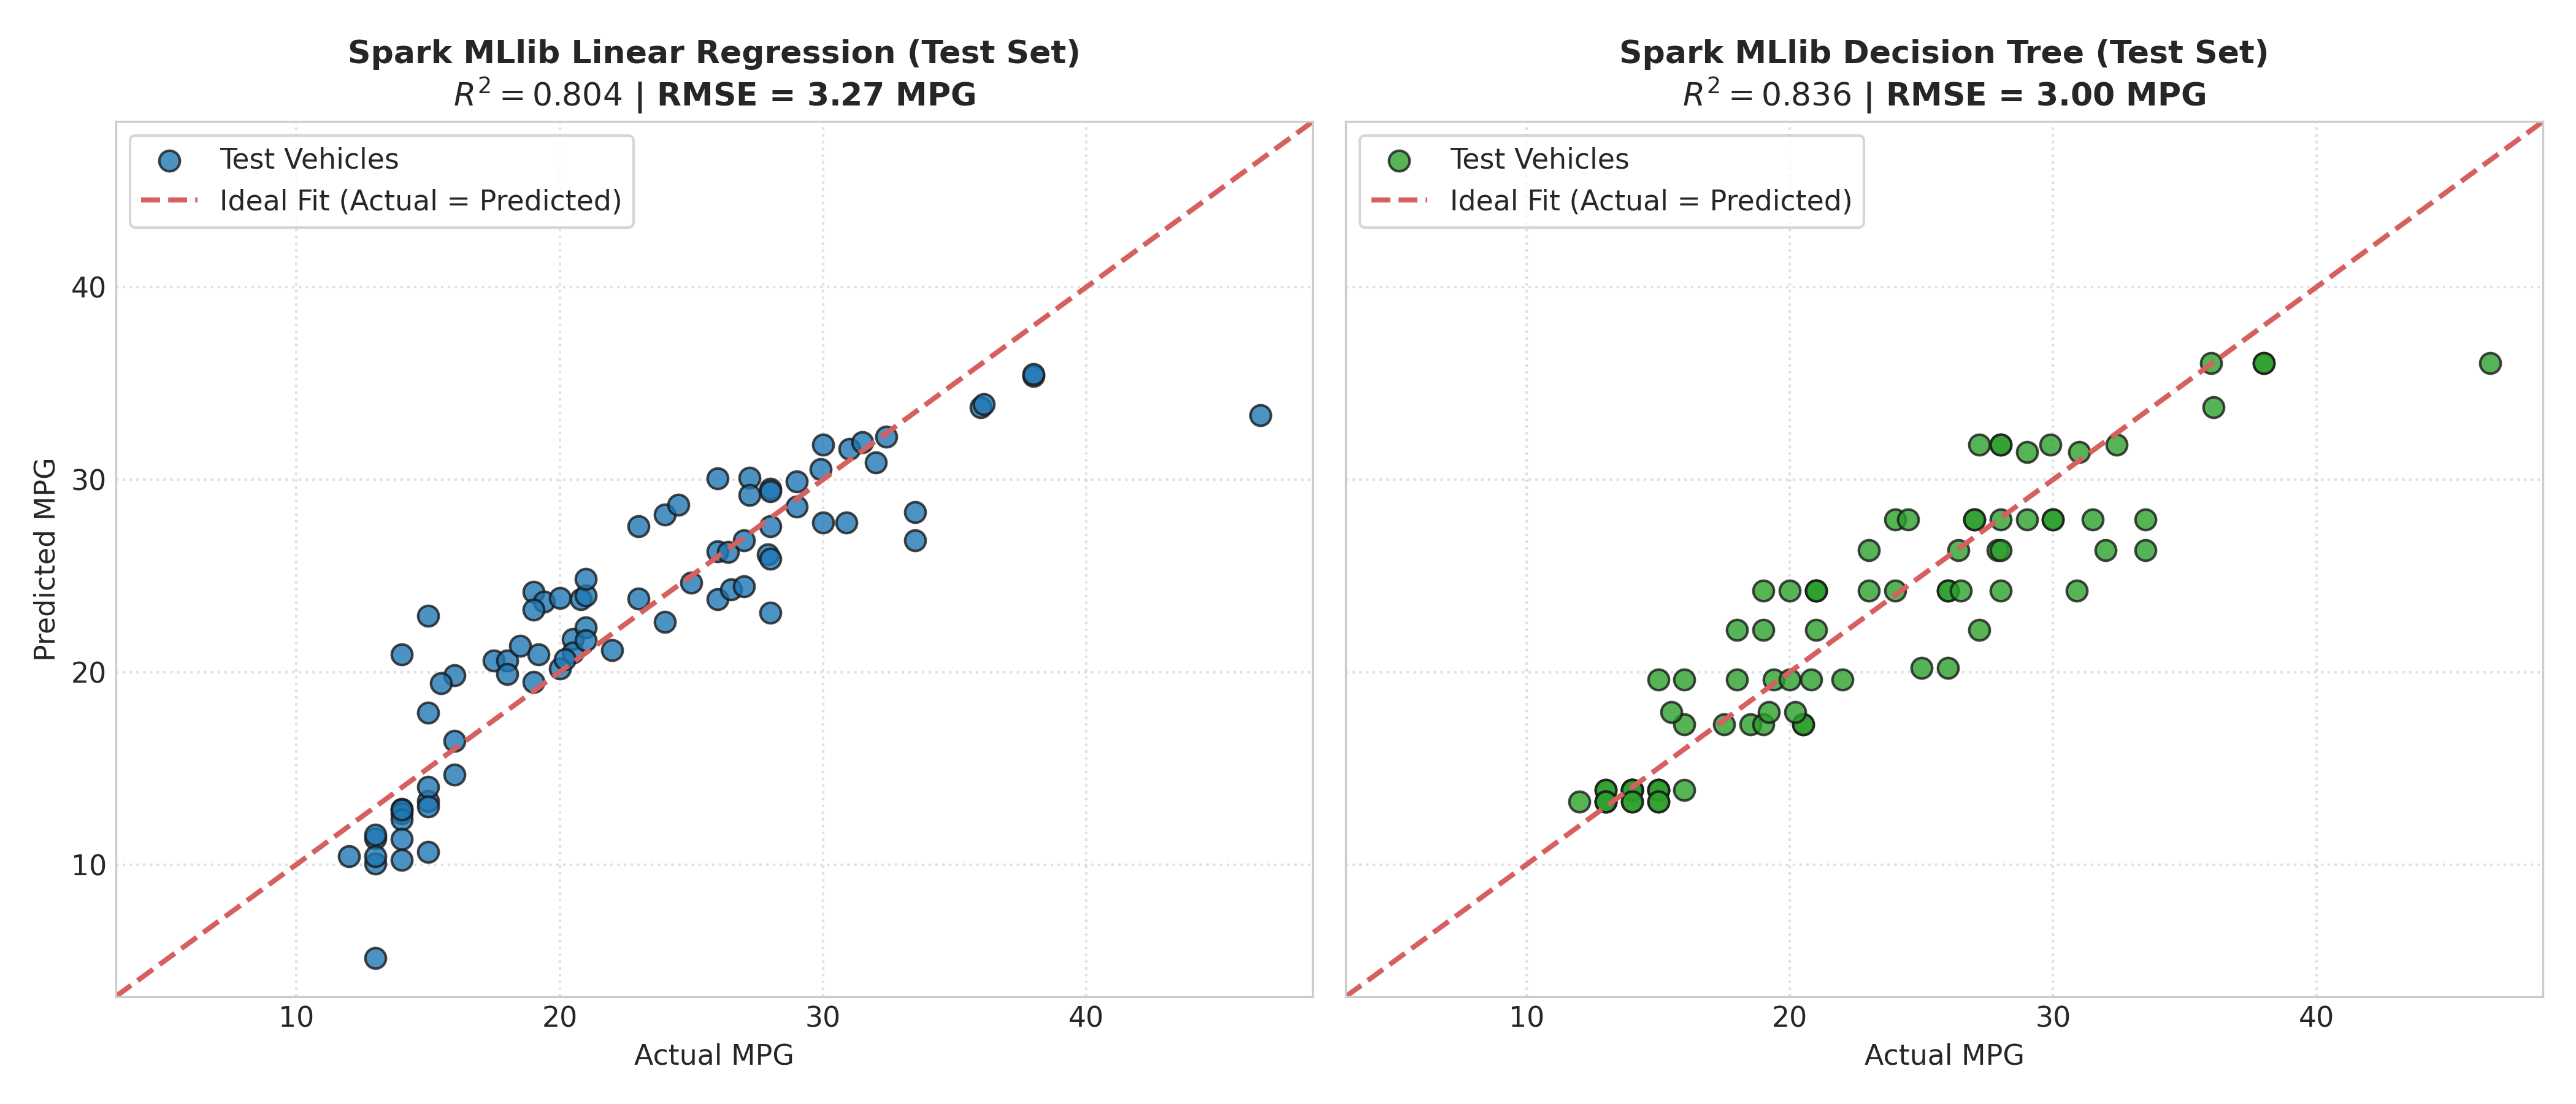

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
min_val = min(test_df["Actual_MPG"].min(), test_df["LR_Pred"].min(), test_df["DT_Pred"].min()) - 2
max_val = max(test_df["Actual_MPG"].max(), test_df["LR_Pred"].max(), test_df["DT_Pred"].max()) + 2

lr_row = metrics_df[metrics_df["Model"].str.contains("Linear Regression")].iloc[0]
dt_row = metrics_df[metrics_df["Model"].str.contains("Standard")].iloc[0]

axes[0].scatter(test_df["Actual_MPG"], test_df["LR_Pred"], alpha=0.8, c="#1f77b4", edgecolors="k", s=65, label="Test Vehicles")
axes[0].plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="Ideal Fit (Actual = Predicted)")
axes[0].set_title(f"Spark MLlib Linear Regression (Test Set)\n$R^2 = {lr_row['Test_R2']:.3f}$ | RMSE = {lr_row['Test_RMSE']:.2f} MPG", fontsize=12.5, fontweight="bold")
axes[0].set_xlabel("Actual MPG", fontsize=11)
axes[0].set_ylabel("Predicted MPG", fontsize=11)
axes[0].set_xlim(min_val, max_val)
axes[0].set_ylim(min_val, max_val)
axes[0].legend(loc="upper left", frameon=True)

axes[1].scatter(test_df["Actual_MPG"], test_df["DT_Pred"], alpha=0.8, c="#2ca02c", edgecolors="k", s=65, label="Test Vehicles")
axes[1].plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="Ideal Fit (Actual = Predicted)")
axes[1].set_title(f"Spark MLlib Decision Tree (Test Set)\n$R^2 = {dt_row['Test_R2']:.3f}$ | RMSE = {dt_row['Test_RMSE']:.2f} MPG", fontsize=12.5, fontweight="bold")
axes[1].set_xlabel("Actual MPG", fontsize=11)
axes[1].set_xlim(min_val, max_val)
axes[1].set_ylim(min_val, max_val)
axes[1].legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig1_actual_vs_predicted.png"), dpi=300)
plt.show()

### Visualization 2: Model Evaluation Metrics Comparison

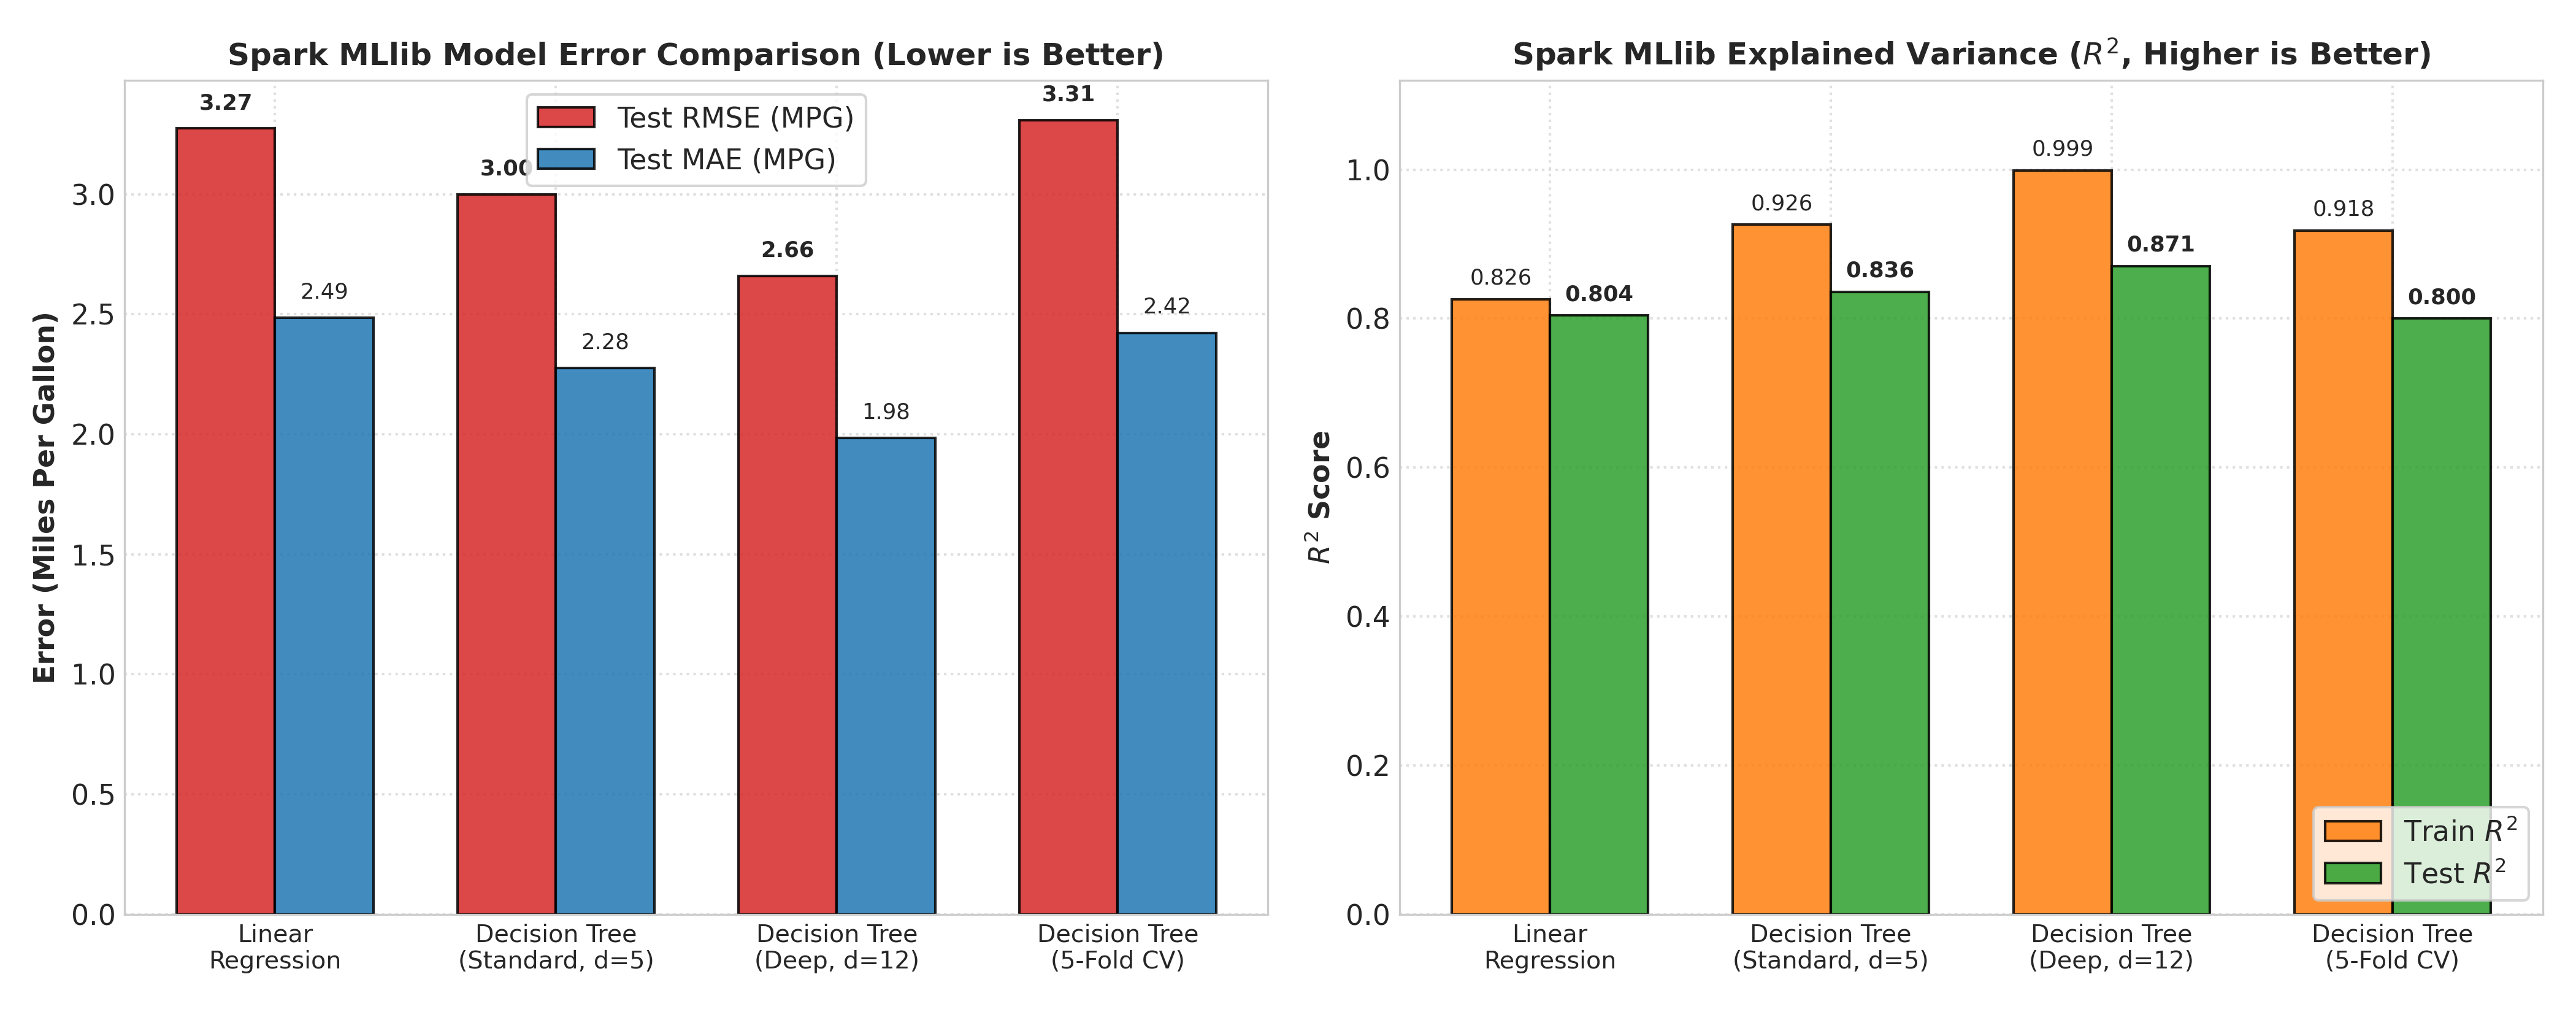

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
short_names = ["Linear\nRegression", "Decision Tree\n(Standard, d=5)", "Decision Tree\n(Deep, d=12)", "Decision Tree\n(5-Fold CV)"]
x_m = np.arange(len(metrics_df))
w_m = 0.35

axes[0].bar(x_m - w_m / 2, metrics_df["Test_RMSE"], w_m, label="Test RMSE (MPG)", color="#d62728", alpha=0.85, edgecolor="black")
axes[0].bar(x_m + w_m / 2, metrics_df["Test_MAE"], w_m, label="Test MAE (MPG)", color="#1f77b4", alpha=0.85, edgecolor="black")
axes[0].set_xticks(x_m)
axes[0].set_xticklabels(short_names, fontsize=9.5)
axes[0].set_ylabel("Error (Miles Per Gallon)", fontsize=11, fontweight="bold")
axes[0].set_title("Spark MLlib Model Error Comparison (Lower is Better)", fontsize=12, fontweight="bold")
axes[0].legend(frameon=True)
for i in range(len(metrics_df)):
    axes[0].text(x_m[i] - w_m / 2, metrics_df["Test_RMSE"].iloc[i] + 0.08, f"{metrics_df['Test_RMSE'].iloc[i]:.2f}", ha="center", fontsize=8.5, fontweight="bold")
    axes[0].text(x_m[i] + w_m / 2, metrics_df["Test_MAE"].iloc[i] + 0.08, f"{metrics_df['Test_MAE'].iloc[i]:.2f}", ha="center", fontsize=8.5)

axes[1].bar(x_m - w_m / 2, metrics_df["Train_R2"], w_m, label="Train $R^2$", color="#ff7f0e", alpha=0.85, edgecolor="black")
axes[1].bar(x_m + w_m / 2, metrics_df["Test_R2"], w_m, label="Test $R^2$", color="#2ca02c", alpha=0.85, edgecolor="black")
axes[1].set_xticks(x_m)
axes[1].set_xticklabels(short_names, fontsize=9.5)
axes[1].set_ylabel("$R^2$ Score", fontsize=11, fontweight="bold")
axes[1].set_ylim(0, 1.12)
axes[1].set_title("Spark MLlib Explained Variance ($R^2$, Higher is Better)", fontsize=12, fontweight="bold")
axes[1].legend(frameon=True, loc="lower right")
for i in range(len(metrics_df)):
    axes[1].text(x_m[i] - w_m / 2, metrics_df["Train_R2"].iloc[i] + 0.02, f"{metrics_df['Train_R2'].iloc[i]:.3f}", ha="center", fontsize=8.5)
    axes[1].text(x_m[i] + w_m / 2, metrics_df["Test_R2"].iloc[i] + 0.02, f"{metrics_df['Test_R2'].iloc[i]:.3f}", ha="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig2_model_metrics_comparison.png"), dpi=300)
plt.show()

### Visualization 3: Subgroup Error Comparison (Cylinders & Weight Categories)

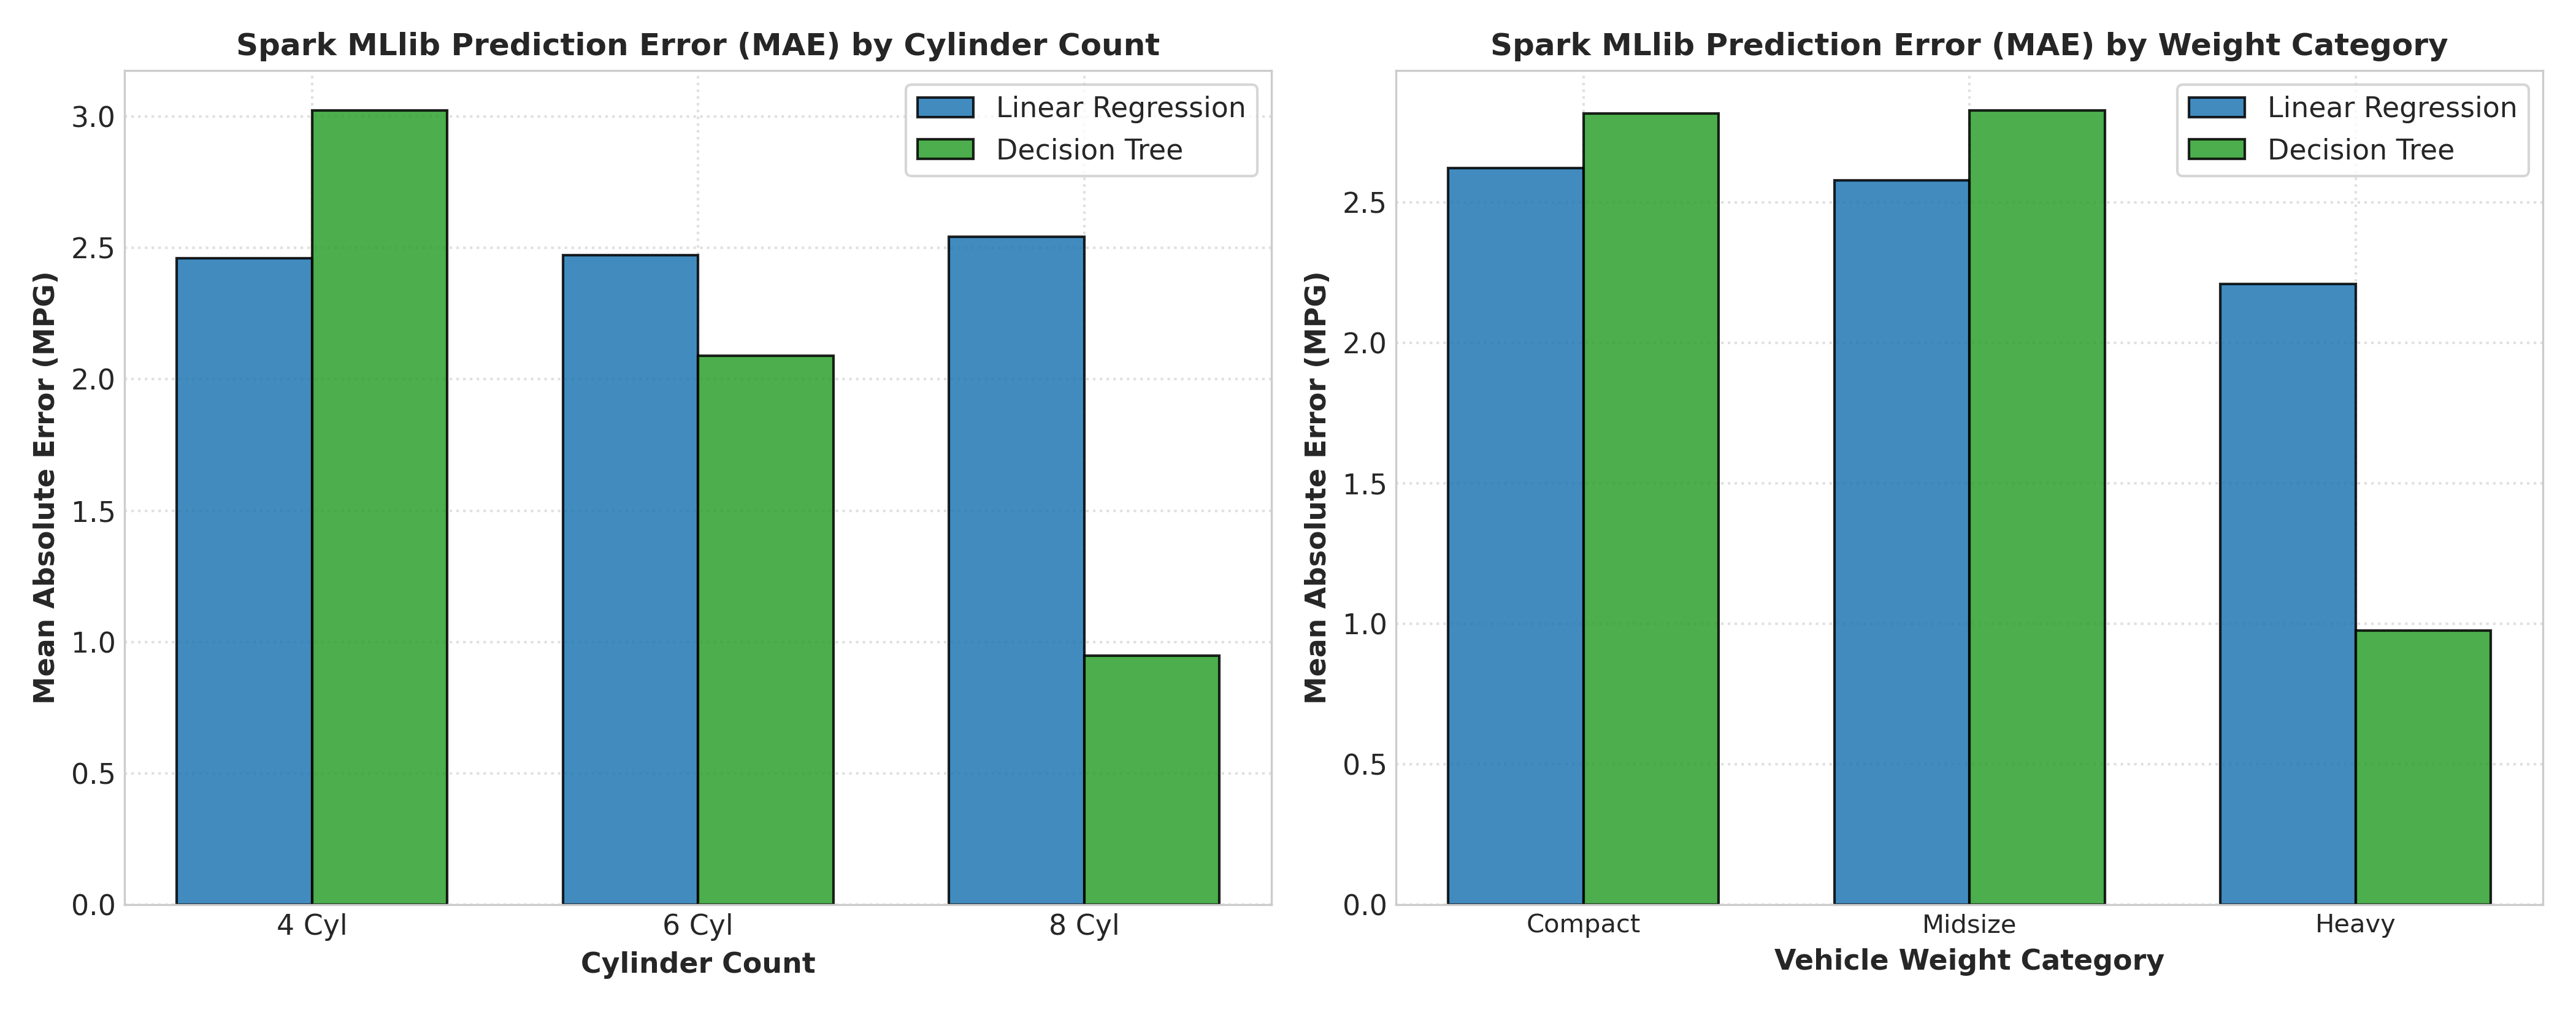

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
width = 0.35

x_c = np.arange(len(cyl_df))
axes[0].bar(x_c - width / 2, cyl_df["LR_MAE"], width, label="Linear Regression", color="#1f77b4", alpha=0.85, edgecolor="black")
axes[0].bar(x_c + width / 2, cyl_df["DT_MAE"], width, label="Decision Tree", color="#2ca02c", alpha=0.85, edgecolor="black")
axes[0].set_xlabel("Cylinder Count", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Mean Absolute Error (MPG)", fontsize=11, fontweight="bold")
axes[0].set_title("Spark MLlib Prediction Error (MAE) by Cylinder Count", fontsize=12, fontweight="bold")
axes[0].set_xticks(x_c)
axes[0].set_xticklabels([f"{c} Cyl" for c in cyl_df["cylinders"]])
axes[0].legend(frameon=True)

weight_order = ["Compact (<2500 lbs)", "Midsize (2500-3500 lbs)", "Heavy (>=3500 lbs)"]
w_plot = weight_df.set_index("weight_category").reindex(weight_order).reset_index()
x_w = np.arange(len(w_plot))
axes[1].bar(x_w - width / 2, w_plot["LR_MAE"], width, label="Linear Regression", color="#1f77b4", alpha=0.85, edgecolor="black")
axes[1].bar(x_w + width / 2, w_plot["DT_MAE"], width, label="Decision Tree", color="#2ca02c", alpha=0.85, edgecolor="black")
axes[1].set_xlabel("Vehicle Weight Category", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Mean Absolute Error (MPG)", fontsize=11, fontweight="bold")
axes[1].set_title("Spark MLlib Prediction Error (MAE) by Weight Category", fontsize=12, fontweight="bold")
axes[1].set_xticks(x_w)
axes[1].set_xticklabels(["Compact", "Midsize", "Heavy"], fontsize=10)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig3_subgroup_errors.png"), dpi=300)
plt.show()

### Visualization 4: Residual Plot & Decision Tree Feature Importances

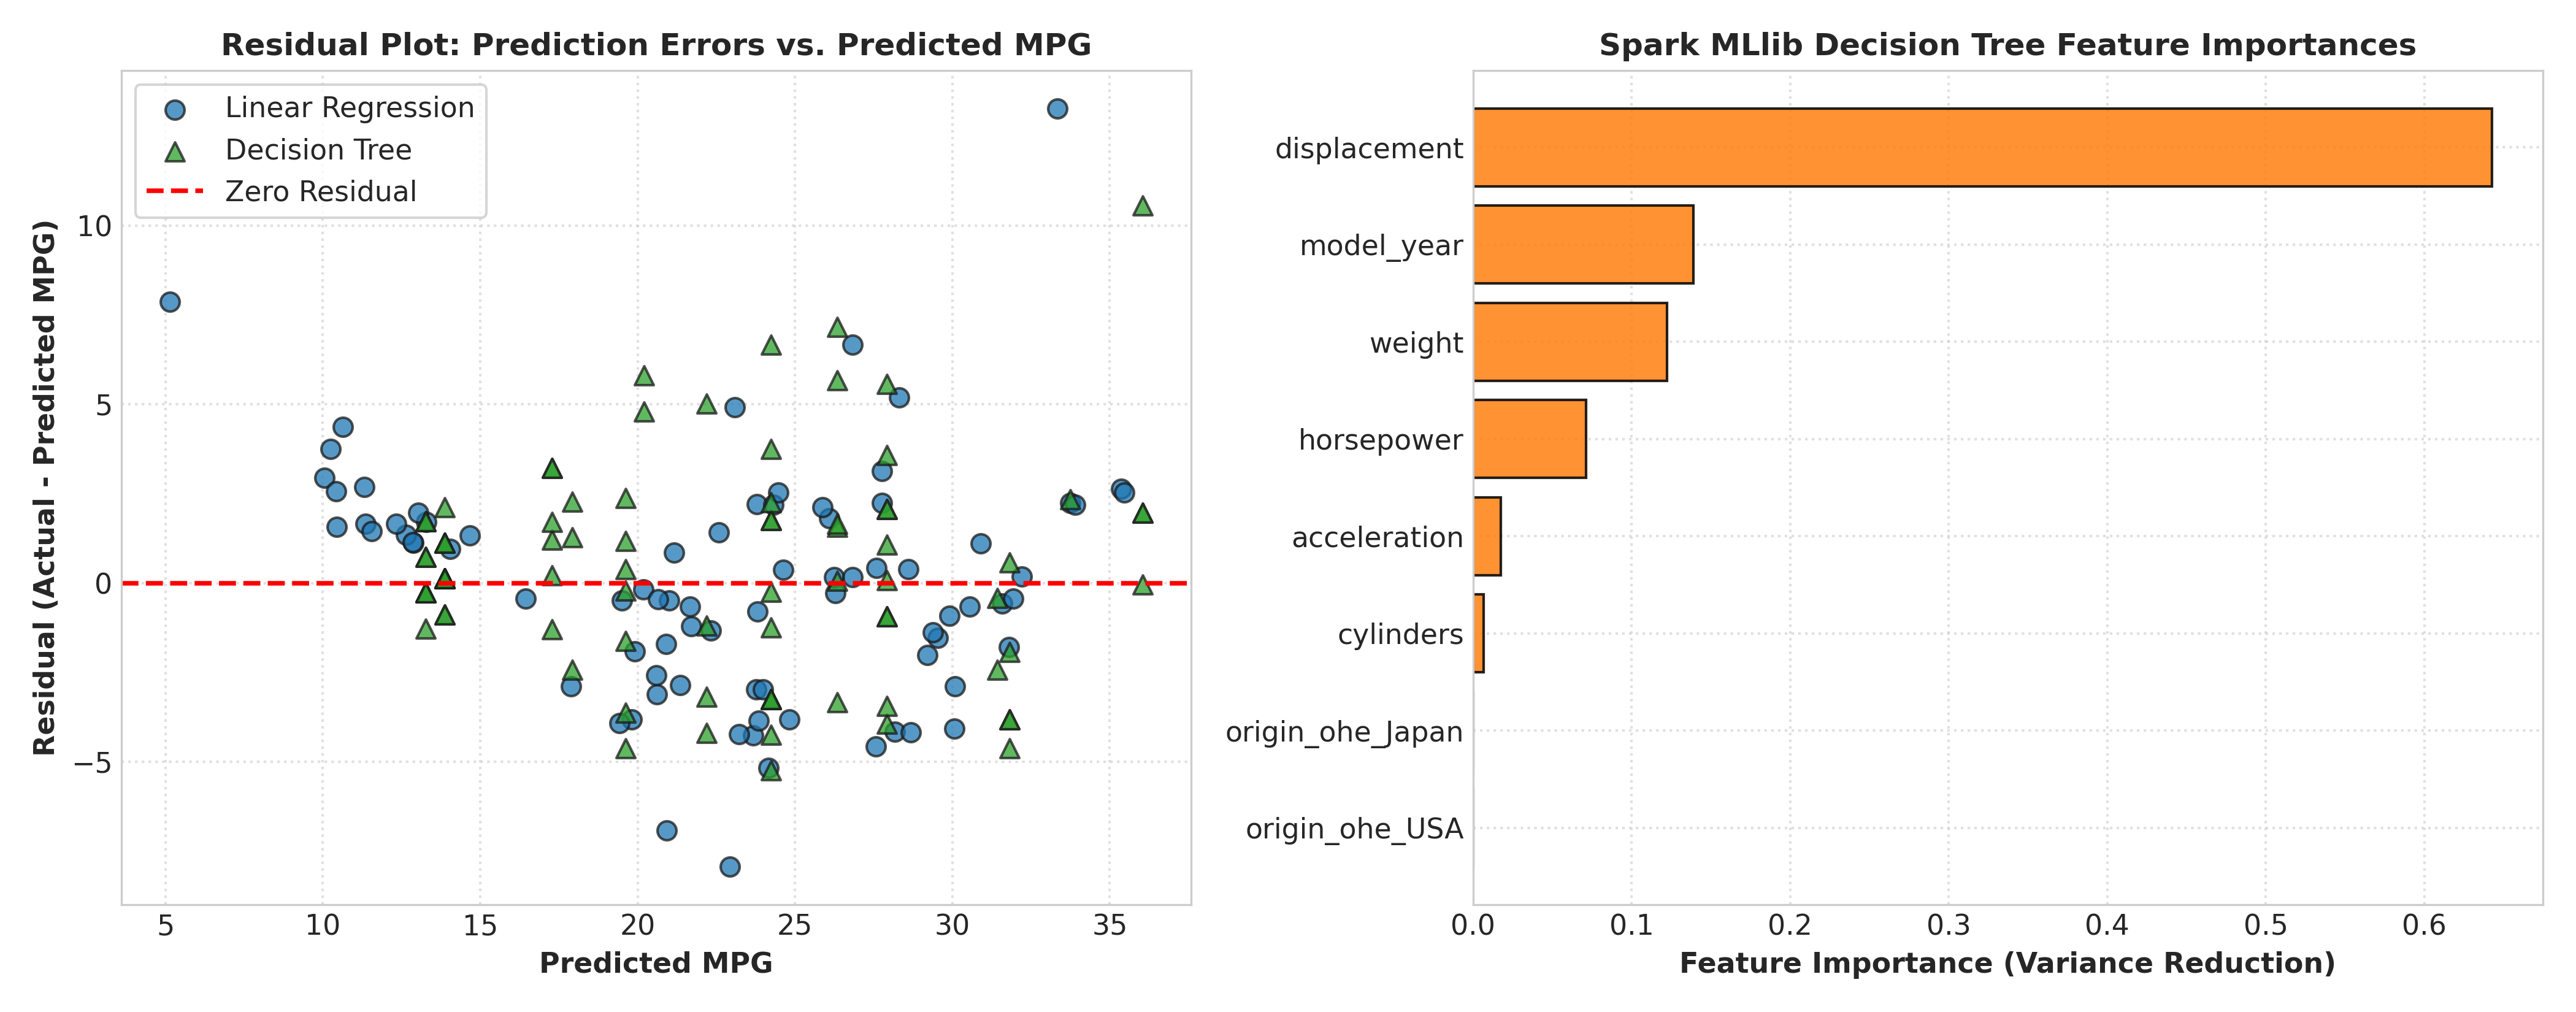

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].scatter(test_df["LR_Pred"], test_df["LR_Residual"], alpha=0.75, c="#1f77b4", edgecolors="k", s=55, label="Linear Regression")
axes[0].scatter(test_df["DT_Pred"], test_df["DT_Residual"], alpha=0.75, c="#2ca02c", edgecolors="k", s=55, marker="^", label="Decision Tree")
axes[0].axhline(0, color="red", linestyle="--", lw=1.8, label="Zero Residual")
axes[0].set_xlabel("Predicted MPG", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Residual (Actual - Predicted MPG)", fontsize=11, fontweight="bold")
axes[0].set_title("Residual Plot: Prediction Errors vs. Predicted MPG", fontsize=12, fontweight="bold")
axes[0].legend(frameon=True)

imp_sorted = imp_df.sort_values("Importance", ascending=True)
axes[1].barh(imp_sorted["Feature"], imp_sorted["Importance"], color="#ff7f0e", alpha=0.85, edgecolor="black")
axes[1].set_xlabel("Feature Importance (Variance Reduction)", fontsize=11, fontweight="bold")
axes[1].set_title("Spark MLlib Decision Tree Feature Importances", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig4_residual_analysis.png"), dpi=300)
plt.show()

### Visualization 5: Feature Distributions, Class Imbalance & Correlation Heatmap

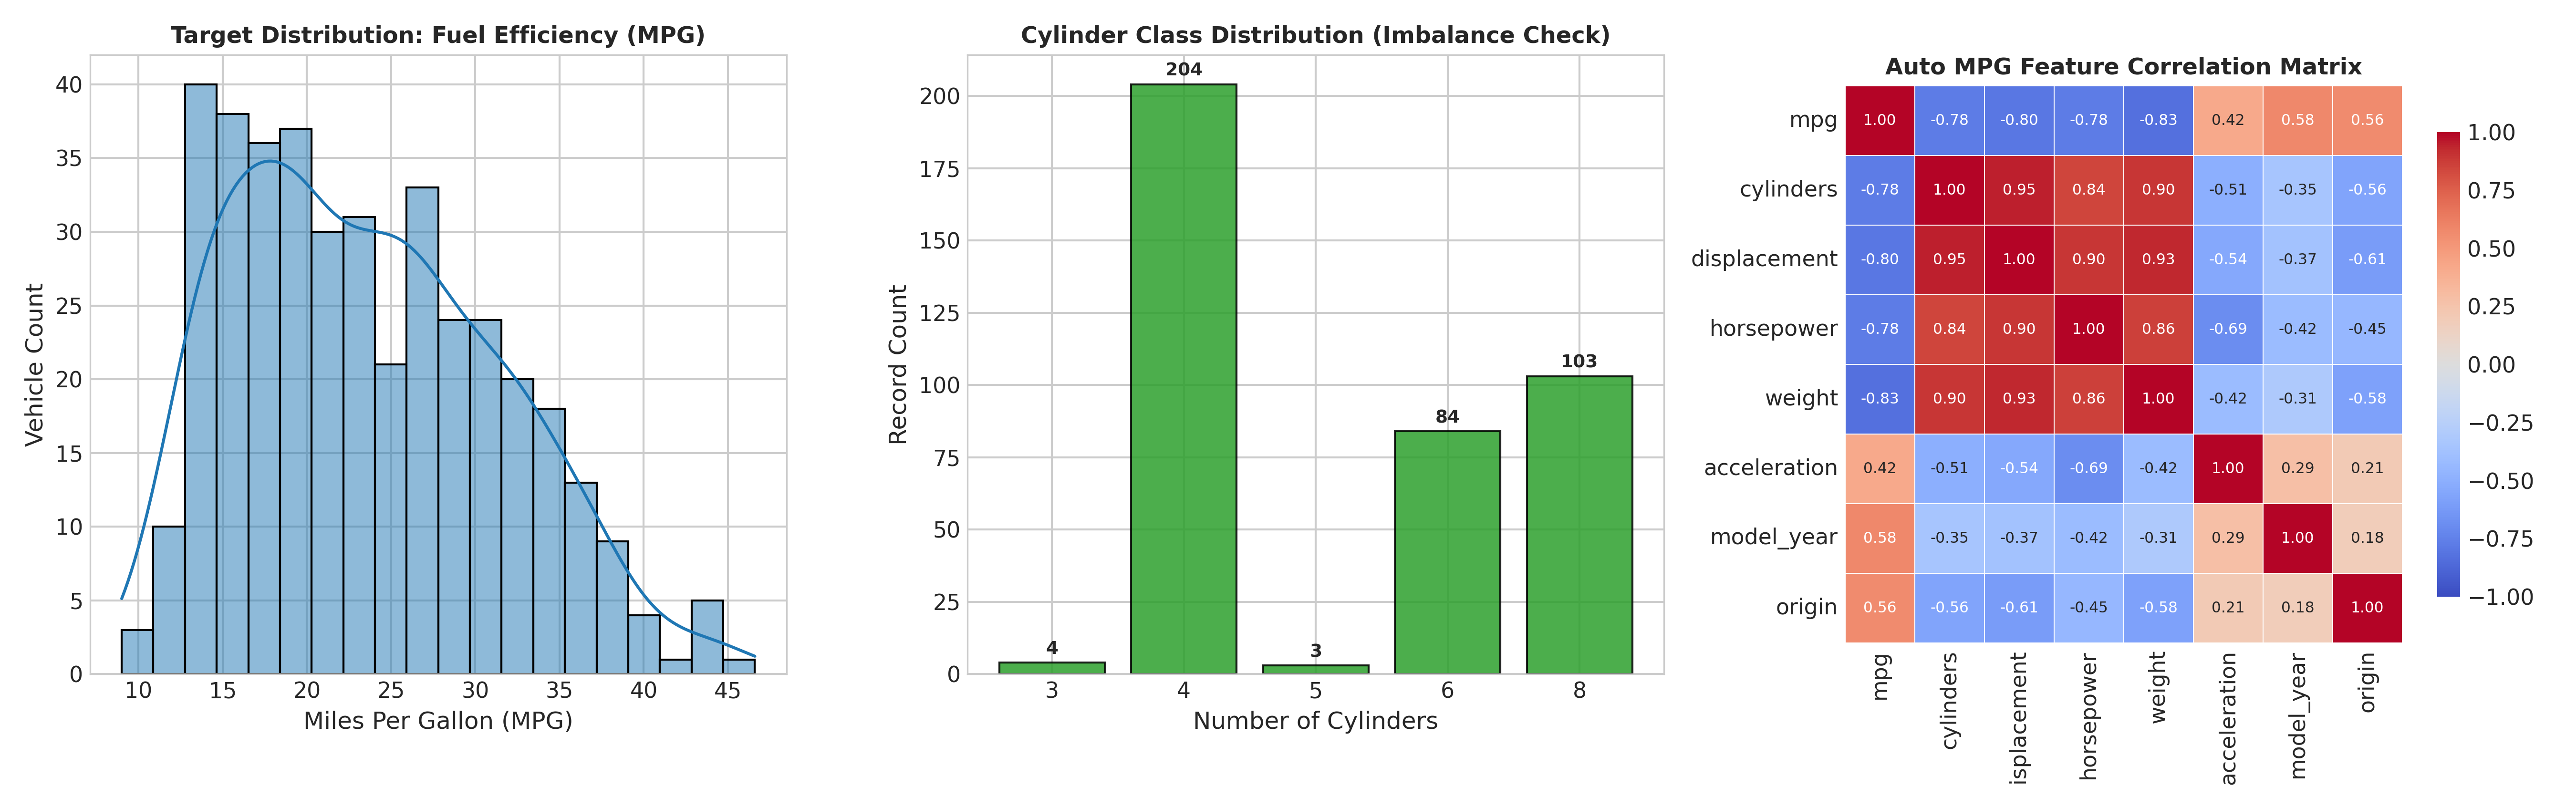

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

sns.histplot(clean_df["mpg"], bins=20, kde=True, ax=axes[0], color="#1f77b4", edgecolor="black")
axes[0].set_title("Target Distribution: Fuel Efficiency (MPG)", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("Miles Per Gallon (MPG)")
axes[0].set_ylabel("Vehicle Count")

cyl_counts = clean_df["cylinders"].value_counts().sort_index()
axes[1].bar(cyl_counts.index.astype(str), cyl_counts.values, color="#2ca02c", alpha=0.85, edgecolor="black")
axes[1].set_title("Cylinder Class Distribution (Imbalance Check)", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("Number of Cylinders")
axes[1].set_ylabel("Record Count")
for idx, val in enumerate(cyl_counts.values):
    axes[1].text(idx, val + 3, str(val), ha="center", fontweight="bold", fontsize=9)

num_cols = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year", "origin"]
corr = clean_df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.4, cbar_kws={"shrink": 0.75}, ax=axes[2], annot_kws={"size": 7.5})
axes[2].set_title("Auto MPG Feature Correlation Matrix", fontsize=11.5, fontweight="bold")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig5_feature_distributions.png"), dpi=300)
plt.show()

### Visualization 6: Sample Vehicle Fuel Efficiency Predictions

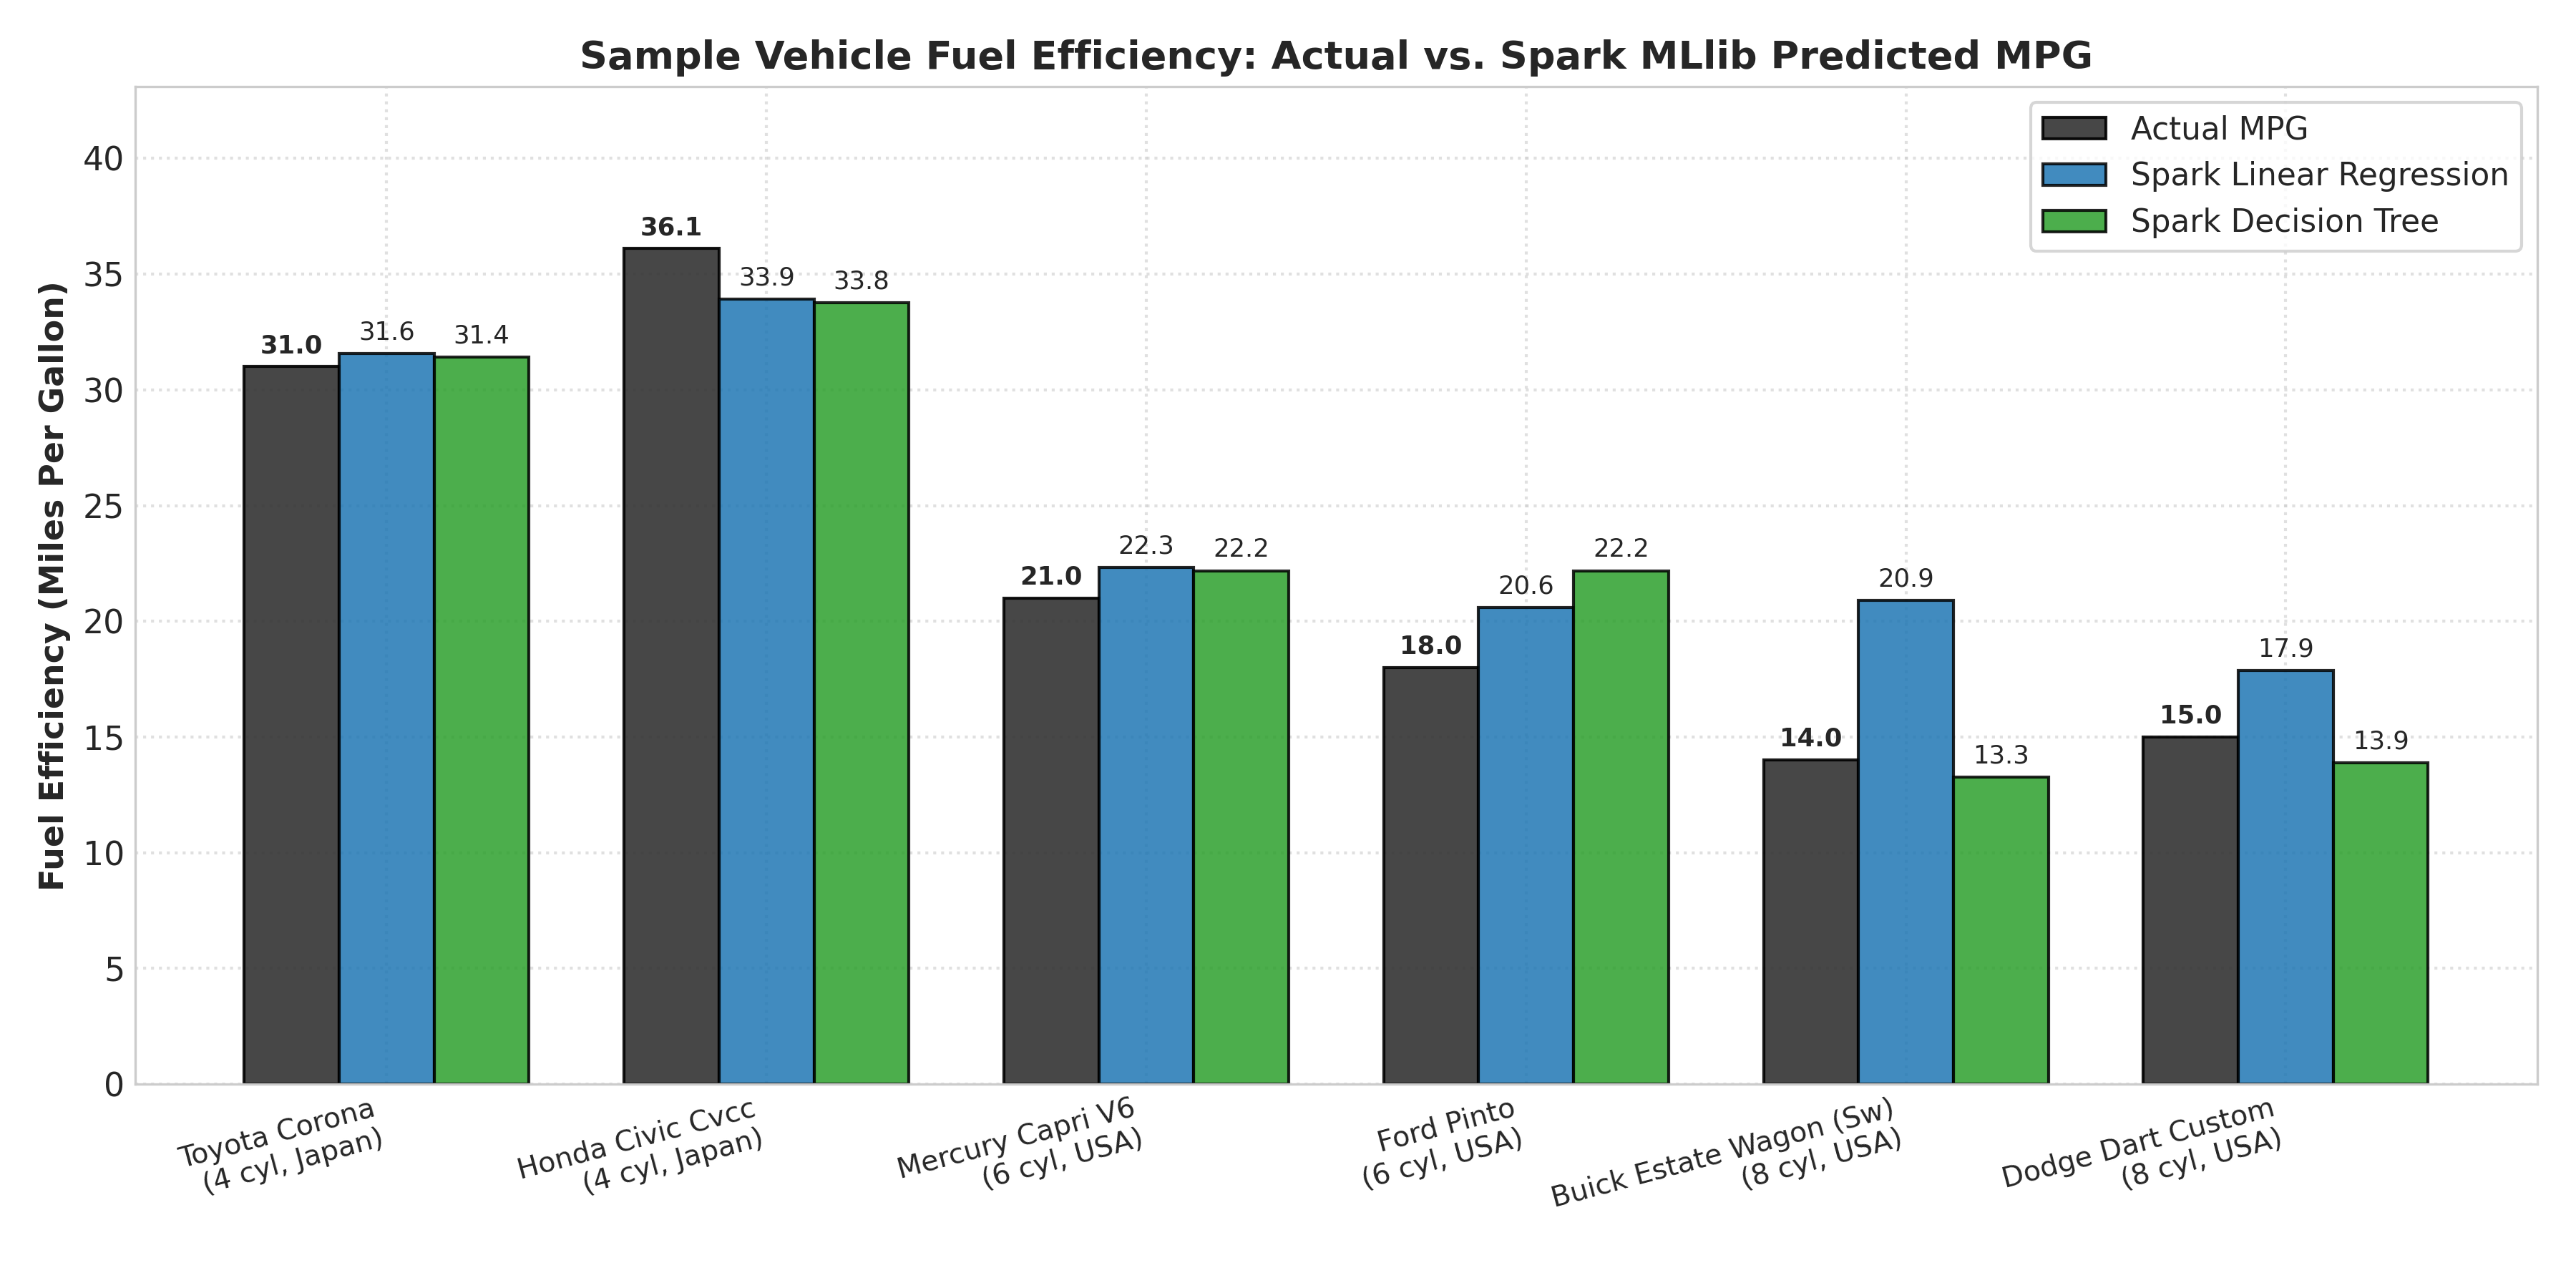

In [11]:
fig, ax = plt.subplots(figsize=(12, 6))
x_s = np.arange(len(samples_df))
w_s = 0.25

ax.bar(x_s - w_s, samples_df["Actual_MPG"], w_s, label="Actual MPG", color="#333333", alpha=0.9, edgecolor="black")
ax.bar(x_s, samples_df["LR_Pred"], w_s, label="Spark Linear Regression", color="#1f77b4", alpha=0.85, edgecolor="black")
ax.bar(x_s + w_s, samples_df["DT_Pred"], w_s, label="Spark Decision Tree", color="#2ca02c", alpha=0.85, edgecolor="black")

labels = [f"{row['car_name'].title()}\n({row['cylinders']} cyl, {row['origin_name']})" for _, row in samples_df.iterrows()]
ax.set_xticks(x_s)
ax.set_xticklabels(labels, rotation=15, ha="right", fontsize=9.5)
ax.set_ylabel("Fuel Efficiency (Miles Per Gallon)", fontsize=11, fontweight="bold")
ax.set_title("Sample Vehicle Fuel Efficiency: Actual vs. Spark MLlib Predicted MPG", fontsize=13, fontweight="bold")
ax.legend(frameon=True, fontsize=10.5)

for i in range(len(samples_df)):
    ax.text(x_s[i] - w_s, samples_df["Actual_MPG"].iloc[i] + 0.6, f"{samples_df['Actual_MPG'].iloc[i]:.1f}", ha="center", fontsize=8.5, fontweight="bold")
    ax.text(x_s[i], samples_df["LR_Pred"].iloc[i] + 0.6, f"{samples_df['LR_Pred'].iloc[i]:.1f}", ha="center", fontsize=8.5)
    ax.text(x_s[i] + w_s, samples_df["DT_Pred"].iloc[i] + 0.6, f"{samples_df['DT_Pred'].iloc[i]:.1f}", ha="center", fontsize=8.5)

ax.set_ylim(0, samples_df["Actual_MPG"].max() + 7)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig6_sample_predictions.png"), dpi=300)
plt.show()

In [12]:
spark.stop()
print("SparkSession stopped cleanly.")

SparkSession stopped cleanly.


## Step 5: Analyze and Explain the Findings
1. **Model Comparison:** On the 81-vehicle test set, Spark MLlib's standard `DecisionTreeRegressor` (`maxDepth=5, minInstancesPerNode=1`) achieved **Test $R^2 = 0.8356$** and **Test RMSE = `3.0004` MPG** (Test MAE = `2.2758`), outperforming `LinearRegression` (**Test $R^2 = 0.8042$**, **Test RMSE = `3.2742` MPG**, Test MAE = `2.4866`).
2. **Preprocessing & Encoding Effects:** Cylinder-median imputation preserved all `398` records (`6` missing `horsepower` `'?'` values). Encoding `origin_name` with `StringIndexer` + `OneHotEncoder` captured the domestic fuel-economy penalty (`origin_ohe_USA = -1.3516`).
3. **Subgroup Patterns & Outliers:** `LinearRegression` achieved lower error on 4-cylinder (`2.4622` vs. `3.0248` MAE) and European cars (`1.8172` vs. `3.0566` MAE), whereas `DecisionTreeRegressor` cut MAE by **63%** on 8-cylinder cars (`0.9476` vs. `2.5437` MAE) and **56%** on heavy vehicles (`0.9756` vs. `2.2107` MAE). On anomalous builds like `buick estate wagon (sw)` (8-cyl, 3,086 lbs, Actual `14.0` MPG), `LinearRegression` overpredicted `20.91` MPG (`49.4%` error) while `DecisionTreeRegressor` split on `displacement` and predicted `13.27` MPG (`5.2%` error).
4. **Class Imbalance & Limitations:** 3-cylinder (`N=4`) and 5-cylinder (`N=3`) records are too rare for standalone subgroup inference, and the 1970–1982 era lacks modern fuel-injection/hybrid features. Future extensions include Spark MLlib `RandomForestRegressor` and `GBTRegressor`.
